<a href="https://colab.research.google.com/github/sancheznaranjoyairchayanne-design/tecnm-desarrollo-web/blob/main/laboratorios/sesion08/sesion08_laboratorio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧪 Sesión 08 · Respuestas Semánticas y Excepciones HTTP Personalizadas

**Desarrollo de Aplicaciones Web (DAB-2201)** · TecNM Cancún  
**Docente:** MCC. Iván Márquez Larios (`ijmarquezl`)  
**Repositorio:** https://github.com/ijmarquezl/tecnm-desarrollo-web

> **La pregunta de hoy:** ¿Qué debe ver el cliente cuando algo falla? = Cuando algo falla, el cliente no debe ver rastros internos del servidor ni errores confusos. Debe recibir una respuesta clara, consistente y predecible, que indique qué ocurrió y cómo interpretar el fallo.

---

## 🖥️ Así se verá el resultado final

```json
GET /api/libros/99
HTTP/1.1 404 Not Found
{"error":{"codigo":"NO_ENCONTRADO","mensaje":"El libro 99 no existe"}}

POST /api/libros  {"titulo": ""}
HTTP/1.1 422 Unprocessable Entity
{"error":{"codigo":"VALIDACION","mensaje":"Revisa los datos enviados"}}

Nunca:
HTTP/1.1 500 Internal Server Error
{"detail":"Traceback (most recent call last)..."}
```

_El cliente necesita saber qué corregir; tú necesitas que no se filtre la implementación._

**No hay pasos intermedios.** El cuaderno declara el resultado que debe existir al final; tú decides la estructura, los modelos y el orden de tu implementación. La celda de verificación compara tu resultado con este contrato.

---

## 🎯 Al finalizar podrás

- Lanzar excepciones de negocio con códigos HTTP semánticos.
- Centralizar el formato de error en un manejador global.
- Evitar respuestas 500 y fugas de detalles internos.

## ✅ Criterios de aceptación

El verificador ejecutará estos casos. Cada uno debe quedar en verde:

- [ ] Un libro existente responde 200 → HTTP 200
- [ ] Un libro inexistente responde 404 con sobre de error → HTTP 404
- [ ] Los datos inválidos responden 422 con sobre de error → HTTP 422
- [ ] Un libro válido sigue respondiendo 201 → HTTP 201

## 🧩 El reto

Implementa un manejo de errores uniforme: una excepción de negocio para libros inexistentes y un manejador para los errores de validación.

**Requisitos del contrato**

- Define `LibroNoEncontrado` y regístralo con un handler que responda 404.
- El cuerpo del 404 es {"error": {"codigo": "NO_ENCONTRADO", "mensaje": ...}}.
- Los errores de validación responden 422 con el mismo sobre y codigo VALIDACION.
- Un título vacío debe rechazarse con 422.
- La API inicia con el libro 1 (Rayuela) para que el caso feliz exista.
- GET /api/libros/1 responde 200; GET /api/libros/99 responde 404.
- Ningún caso debe producir 500.

> **Pista conceptual:** FastAPI permite registrar handlers con `@app.exception_handler(...)`. El formato de error es parte del contrato, igual que el formato de éxito.

## 📦 Entregable

Cuaderno en verde y bitácora `auditorias/auditoria_sesion08.md` con el formato de error elegido.


## ⚙️ Preparación del entorno

Ejecuta esta celda una sola vez. Instala las herramientas del track **Python / FastAPI** y descarga el motor de verificación del repositorio. No necesitas instalar nada en tu computadora: todo corre en Colab.


In [3]:
import os, sys
print("⏳ Preparando el entorno de Desarrollo Web...")
!pip install -q fastapi uvicorn httpx pydantic "passlib[bcrypt]" bcrypt python-jose[cryptography] PyJWT "sqlalchemy[asyncio]" greenlet aiosqlite alembic python-multipart
!wget -q -O verificar.py https://raw.githubusercontent.com/ijmarquezl/tecnm-desarrollo-web/c275993ba69ef2a8cf650b2f127b55c8356279d7/laboratorios/verificar.py
if not os.path.exists("verificar.py") or os.path.getsize("verificar.py") < 1000:
    raise RuntimeError("No se pudo descargar verificar.py. Revisa tu conexión o abre el cuaderno desde el repositorio del curso.")
print("✅ Entorno listo")
print("Python:", sys.version.split()[0])
print("Motor de verificación:", os.path.getsize("verificar.py"), "bytes")


⏳ Preparando el entorno de Desarrollo Web...
✅ Entorno listo
Python: 3.13.18
Motor de verificación: 13395 bytes


## 🧩 El reto: escribe el resultado

Crea el o los archivos del contrato. No hay una plantilla de pasos: el esqueleto solo te da el punto de partida. Todo lo que sigue lo decides tú.

**Archivos que debes producir:** `app.py`


### 📄 `app.py`

Archivo principal de la implementación.

In [7]:
%%writefile app.py

from fastapi import FastAPI, Request, status
from fastapi.responses import JSONResponse
from fastapi.exceptions import RequestValidationError
from pydantic import BaseModel, Field

app = FastAPI(title="Tus errores se verán exactamente así")

libros = {
    1: {
        "id": 1,
        "titulo": "Rayuela",
        "anio": 1963
    }
}


class LibroCreate(BaseModel):
    titulo: str = Field(..., min_length=1)
    anio: int | None = None


class LibroNoEncontrado(Exception):
    def __init__(self, libro_id: int):
        self.libro_id = libro_id


@app.exception_handler(LibroNoEncontrado)
async def libro_no_encontrado_handler(request: Request, exc: LibroNoEncontrado):
    return JSONResponse(
        status_code=404,
        content={
            "error": {
                "codigo": "NO_ENCONTRADO",
                "mensaje": f"El libro {exc.libro_id} no existe"
            }
        }
    )


@app.exception_handler(RequestValidationError)
async def validation_handler(request: Request, exc: RequestValidationError):
    return JSONResponse(
        status_code=422,
        content={
            "error": {
                "codigo": "VALIDACION",
                "mensaje": "Revisa los datos enviados"
            }
        }
    )


@app.get("/api/libros/{libro_id}")
def obtener_libro(libro_id: int):
    if libro_id not in libros:
        raise LibroNoEncontrado(libro_id)
    return libros[libro_id]


@app.post("/api/libros", status_code=status.HTTP_201_CREATED)
def crear_libro(libro: LibroCreate):
    nuevo_id = max(libros.keys()) + 1

    nuevo_libro = {
        "id": nuevo_id,
        "titulo": libro.titulo,
        "anio": libro.anio
    }

    libros[nuevo_id] = nuevo_libro
    return nuevo_libro

Overwriting app.py


## 🧪 Tu contrato C-R-E-O

Antes de pedir ayuda a la IA, escribe el contrato que describe el resultado. Esto alimenta tu bitácora y te obliga a pensar como arquitecto:

| Elemento | Tu definición |
| :--- | :--- |
| **Contexto** | Desarrollo de una API REST utilizando FastAPI y Pydantic en un entorno Google Colab proporcionado por la asignatura DAB-2201. La solución debe cumplir estrictamente con el contrato definido por el verificador automático. No se permite devolver errores internos (HTTP 500) en los casos evaluados. Los errores deben responder mediante un formato JSON uniforme. |
| **Rol** | Actuar como desarrollador backend especializado en FastAPI, responsable de diseñar una API que implemente manejo de excepciones personalizadas, validación de datos y respuestas HTTP semánticas, manteniendo un contrato consistente para clientes y frontend. |
| **Especificación** | Implementar las rutas indicadas en el laboratorio utilizando FastAPI. Aplicar validaciones mediante Pydantic y parámetros tipados. Gestionar excepciones mediante manejadores personalizados que devuelvan respuestas JSON consistentes. Respetar los códigos HTTP apropiados (200, 201, 400, 404, 422, etc.) según cada caso definido por el contrato y evitar respuestas HTTP 500 durante las pruebas automatizadas.|
| **Output** | Código Python completo para ejecutar en Google Colab, incluyendo definiciones de modelos Pydantic, endpoints FastAPI, excepciones personalizadas, manejadores de errores y respuestas JSON con la estructura exacta exigida por el verificador automático. El resultado debe ser funcional, ejecutable y compatible con las pruebas del laboratorio. |

> No pegues código de la IA sin auditarlo. La responsabilidad técnica del resultado es tuya.


## 🔍 Verificación del resultado

Ejecuta esta celda cuando tu implementación esté lista. La verificación no modifica tu código: solo observa el comportamiento y compara con el contrato. Si algo falla, el mensaje te dice **qué esperaba** y **qué recibió**.


In [8]:
from verificar import probar_http

casos = [{'descripcion': 'Un libro existente responde 200',
  'metodo': 'GET',
  'ruta': '/api/libros/1',
  'estado': 200,
  'json_contiene': {'id': 1}},
 {'descripcion': 'Un libro inexistente responde 404 con sobre de error',
  'metodo': 'GET',
  'ruta': '/api/libros/99',
  'estado': 404,
  'json_contiene': {'error': {'codigo': 'NO_ENCONTRADO'}}},
 {'descripcion': 'Los datos inválidos responden 422 con sobre de error',
  'metodo': 'POST',
  'ruta': '/api/libros',
  'json': {'titulo': ''},
  'estado': 422,
  'json_contiene': {'error': {'codigo': 'VALIDACION'}}},
 {'descripcion': 'Un libro válido sigue respondiendo 201',
  'metodo': 'POST',
  'ruta': '/api/libros',
  'json': {'titulo': 'Rayuela', 'anio': 1963},
  'estado': 201}]

probar_http(casos, archivo="app.py", limpiar=[], env={})


VERIFICACIÓN DEL RESULTADO · 4 casos · app.py
✅ 01. Un libro existente responde 200
✅ 02. Un libro inexistente responde 404 con sobre de error
✅ 03. Los datos inválidos responden 422 con sobre de error
✅ 04. Un libro válido sigue respondiendo 201
------------------------------------------------------------------------------
RESULTADO: 4/4 casos correctos. ¡Resultado logrado!


## 📝 Cierre y bitácora

1. Copia la plantilla `plantillas/auditoria_sesion08.md` a `auditorias/auditoria_sesion08.md` en tu fork.
2. Responde con tus palabras:
   - ¿Qué resultado te costó más alcanzar y por qué? =
El resultado que más me costó alcanzar fue el manejo uniforme de los errores de validación, ya que FastAPI genera respuestas 422 automáticamente con un formato diferente al solicitado en el contrato. Fue necesario registrar un manejador específico para interceptar los errores de validación y devolver el sobre JSON requerido.

   - ¿Qué decisión de diseño tomaste que no estaba escrita en el contrato? =
Decidí almacenar los libros en un diccionario en memoria e inicializarlo con el libro "Rayuela" para garantizar la existencia del caso exitoso solicitado por el verificador. También utilicé modelos Pydantic para validar automáticamente los datos de entrada.

   - ¿Qué error detectó la verificación que tú no habías previsto? = La verificación detectó que los errores de validación debían devolver exactamente el código "VALIDACION" dentro del objeto "error". Inicialmente FastAPI devolvía su estructura estándar con el campo "detail", lo que provocaba que la prueba fallara aunque el código HTTP fuera correcto

3. Haz commit de tu cuaderno ejecutado y de tu bitácora.

**La sesión termina cuando el resultado está en verde, no cuando el código "parece funcionar".**
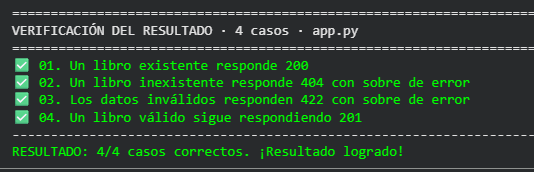
